# Thị trường theo khu vực

| # | Câu hỏi|
|---|---|
| 1 | Hệ thống phủ bao nhiêu thị trường và mức độ tập trung theo địa lý ra sao? | 
| 2 | Quy mô thị trường theo bang như thế nào? | 
| 3 | Quy mô thị trường theo 5 vùng kinh tế như thế nào? | 
| 4 | Khách hàng ở đâu chi tiêu nhiều hơn trên mỗi đơn? |
| 5 | Khu vực nào đang tăng trưởng nhanh nhất, vùng nào tạo phần tăng thêm? |
| 6 | Thành phố nào là thị trường trọng điểm? Khách hàng phân bố ra sao trên bản đồ? |
| 7 | Nguồn cung (người bán) có nằm gần nhu cầu (khách hàng) không? | 
| 8 | Phục vụ vùng xa tốn bao nhiêu phí ship, có liên quan đến thiếu người bán tại chỗ? | 
| 9 | Mỗi vùng mua gì khác biệt so với cả nước? | 
| 10 | Nên ưu tiên mở rộng ở bang nào? | 

### Quy ước
- **Đối tượng phân tích:** Đơn hàng (doanh thu, đơn, khách) và dòng sản phẩm (ngành hàng, luồng người bán → khách).
- **Đơn hợp lệ** = đơn có sản phẩm và trạng thái khác `canceled` / `unavailable`. Mọi chỉ số doanh thu chỉ tính đơn hợp lệ.
- **Doanh thu (GMV)** = `price + freight_value` của các sản phẩm trong đơn (BRL). **Doanh thu hàng hóa** = chỉ `price`.
- **Khách hàng** = `customer_unique_id` (số khách unique).
- **AOV** (giá trị đơn trung bình) = GMV / số đơn.
- **Vị trí khách** = bang/thành phố trong `dim_customer`; **vị trí người bán** = bang trong `dim_seller`.
- **Vùng** = 5 vùng kinh tế của Brazil (IBGE): Sudeste, Sul, Nordeste, Centro-Oeste, Norte.
- **So sánh tăng trưởng**: kỳ này so với cùng kỳ năm trước; kỳ được suy ra từ dữ liệu trong `common.connect()` và in ở §0
  (hiện là 01–08/2018 so với 01–08/2017, vì 2016 rất ít dữ liệu và 09–10/2018 chưa đủ tháng).
  Biểu đồ tăng trưởng theo bang và ma trận cơ hội chỉ gồm các bang có **≥100 đơn trong cùng kỳ năm trước**, để % tăng trưởng không bị nhiễu.

## 0. Kết nối lakehouse & nạp dữ liệu Silver

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from common import *   # kết nối, kỳ phân tích, bảng màu, vùng, hàm trục

# Dân số ước tính 2018 theo bang (IBGE, triệu người, làm tròn) — dữ liệu tham chiếu bên ngoài,
# chỉ dùng để tính mức độ thâm nhập thị trường (đơn / 100.000 dân) ở phần 10.
# (seed state_population.csv của Gold, đổi sang triệu người).
POP_2018_M = {state: people / 1e6 for state, people in STATE_POPULATION_2018.items()}
MIN_STATE_ORDERS_PREV = GOLD.STATE_MATRIX_MIN_PY_ORDERS   # bang đủ lớn để tính % tăng trưởng: ≥ 100 đơn trong cùng kỳ năm trước (§5, §10)
BR_BOX = (-74, -34, -34, 5.5)          # khung lãnh thổ Brazil: kinh độ min, max, vĩ độ min, max (bản đồ §6)
CITY_MARKS = (1, 10, 100, 1000)        # mốc "top k thành phố" trên đường lũy kế §6
TOP_N = GOLD.TOP_FLOW_CATEGORY_N       # số ngành hàng trong heatmap LQ §9 (= is_top12_category của Gold, trang p7)

con, P = connect(["dim_seller", "dim_product", "dim_category", "dim_geolocation"], extra_state_cols={"pop_m": POP_2018_M})
apply_theme()

Kỳ này 01–08/2018 | cùng kỳ 01–08/2017 | xu hướng 01/2017–08/2018 | 98,059 đơn, 96,817 đơn hợp lệ


In [2]:
# Bộ chỉ số kinh doanh dùng chung trong mọi GROUP BY của notebook
BIZ_METRICS = ("count(*) AS orders, count(DISTINCT customer_unique_id) AS customers, "
               "sum(gmv) AS revenue, avg(gmv) AS aov, sum(freight_value) / sum(product_value) AS freight_ratio")

### Tạo bảng phân tích theo địa lý
- `sales`: view các **đơn hợp lệ** của `order_base` (tạo sẵn trong `connect()`), thêm tọa độ của khách. Gồm thời gian mua, bang/thành phố/vùng của khách, GMV, giá trị hàng, phí ship, số sản phẩm.
- `item_ps`: **1 dòng / sản phẩm trong đơn hợp lệ** (`create_item_ps()` của `common/tables.py`), gồm bang/vùng của người bán và của khách, ngành hàng. Dùng cho phân tích cung – cầu và cơ cấu ngành hàng.

In [3]:
con.execute("""
CREATE OR REPLACE TABLE sales AS
SELECT o.*, g.latitude, g.longitude
FROM order_base o LEFT JOIN dim_geolocation g ON g.geolocation_key = o.geolocation_key
WHERE o.is_valid = 1
""")
create_item_ps()
print(q("""SELECT (SELECT count(*) FROM order_base) AS all_orders, (SELECT count(*) FROM sales) AS valid_orders,
                  (SELECT count(*) FROM item_ps) AS valid_items,
                  (SELECT min(purchase_month) FROM sales) AS first_month, (SELECT max(purchase_month) FROM sales) AS last_month""")
      .to_string(index=False))

 all_orders  valid_orders  valid_items first_month last_month
      98059         96817       110500  2016-09-01 2018-09-01


## 1. KPI địa lý
*Câu hỏi: "Hệ thống đang phủ bao nhiêu thị trường và doanh thu tập trung đến mức nào?"*

Chỉ gồm KPI về **độ phủ và mức tập trung địa lý**; quy mô toàn sàn (GMV, đơn, khách, AOV) xem `executive_overview` §1.

In [4]:
kpi = {
    **q(f"SELECT {BIZ_METRICS}, count(DISTINCT customer_state) AS states, "
        "count(DISTINCT customer_state || '|' || customer_city) AS cities FROM sales").iloc[0].to_dict(),
    # CASE thay cho FILTER: Trino 440 lỗi nội bộ khi FILTER so cột chuỗi với hằng số
    **q("""SELECT sum(CASE WHEN customer_state = 'SP' THEN gmv END) / sum(gmv) AS sp_share,
                  sum(CASE WHEN customer_region = 'Sudeste' THEN gmv END) / sum(gmv) AS sudeste_share
           FROM sales""").iloc[0].to_dict(),
    **q("""WITH c AS (SELECT customer_state, customer_city, sum(gmv) AS rev FROM sales GROUP BY 1, 2)
           SELECT (SELECT sum(rev) FROM (SELECT rev FROM c ORDER BY rev DESC LIMIT 10)) / sum(rev) AS top10_city_share
           FROM c""").iloc[0].to_dict(),
    **q("""SELECT count(DISTINCT seller_key) AS sellers, count(DISTINCT seller_state) AS seller_states,
                  sum(gmv) FILTER (WHERE seller_state <> customer_state) / sum(gmv) AS cross_state_share
           FROM item_ps""").iloc[0].to_dict(),
}
labels = {
    "states": ("Số bang có khách", "{:.0f}"),
    "cities": ("Số thành phố có khách", "{:,.0f}"),
    "sellers": ("Số người bán có đơn", "{:,.0f}"),
    "seller_states": ("Số bang có người bán", "{:.0f}"),
    "sp_share": ("% doanh thu từ bang SP", "{:.1%}"),
    "sudeste_share": ("% doanh thu từ vùng Sudeste", "{:.1%}"),
    "top10_city_share": ("% doanh thu từ 10 thành phố lớn nhất", "{:.1%}"),
    "cross_state_share": ("% doanh thu người bán khác bang với khách", "{:.1%}"),
}
print(pd.DataFrame([(lbl, fmt.format(kpi[k])) for k, (lbl, fmt) in labels.items()],
                   columns=["Chỉ số", "Giá trị"]).to_string(index=False))

                                   Chỉ số Giá trị
                         Số bang có khách      27
                    Số thành phố có khách   4,280
                      Số người bán có đơn   3,042
                     Số bang có người bán      23
                   % doanh thu từ bang SP   37.4%
              % doanh thu từ vùng Sudeste   64.6%
     % doanh thu từ 10 thành phố lớn nhất   33.3%
% doanh thu người bán khác bang với khách   69.8%


> **🔎 Kết quả chính**
> - Khách có mặt ở đủ **27 bang** và 4.298 thành phố, nhưng người bán chỉ ở **23 bang**.
> - Doanh thu tập trung rất mạnh: riêng bang **SP chiếm 37,4%**, vùng **Sudeste 64,6%**, và **10 thành phố** lớn nhất chiếm **33,3%**.
> - **69,8%** doanh thu đến từ đơn mà người bán ở bang khác với khách: phần lớn hàng phải vận chuyển liên bang.

## 2. Quy mô thị trường theo bang
*Câu hỏi: "Bang nào mang lại nhiều doanh thu nhất?"*

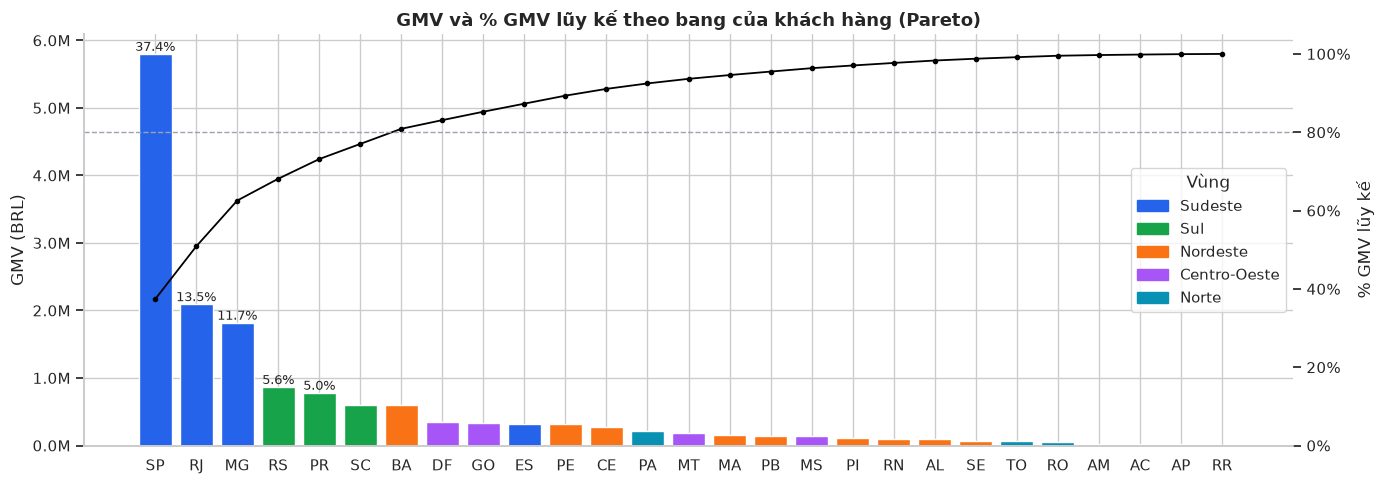

7 bang tạo ra 80% doanh thu
state       region  orders  customers   revenue   aov freight_ratio rev_share cum_share
   SP      Sudeste   40536      39175 5799314.0 143.1         13.8%     37.4%     37.4%
   RJ      Sudeste   12562      12108 2093296.0 166.6         16.8%     13.5%     50.8%
   MG      Sudeste   11333      10970 1818633.0 160.5         17.1%     11.7%     62.5%
   RS          Sul    5330       5151  865187.0 162.3         18.1%      5.6%     68.1%
   PR          Sul    4901       4747  780435.0 159.2         17.3%      5.0%     73.1%
   SC          Sul    3543       3443  600595.0 169.5         17.2%      3.9%     77.0%
   BA     Nordeste    3298       3198  600148.0 182.0         19.6%      3.9%     80.9%
   DF Centro-Oeste    2081       2017  343332.0 165.0         16.8%      2.2%     83.1%
   GO Centro-Oeste    1959       1900  333529.0 170.3         18.3%      2.1%     85.2%
   ES      Sudeste    1992       1925  318797.0 160.0         18.1%      2.1%     87.3%
   P

In [5]:
state = q(f"""SELECT customer_state AS state, arbitrary(customer_region) AS region, {BIZ_METRICS}
              FROM sales GROUP BY 1 ORDER BY revenue DESC""")
state["rev_share"] = state.revenue / state.revenue.sum()
state["cum_share"] = state.rev_share.cumsum()
state["order_share"] = state.orders / state.orders.sum()

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(state.state, state.revenue, color=state.region.map(REGION_COLORS))
brl_axis(ax); ax.set_ylabel("GMV (BRL)")
ax2 = ax.twinx(); ax2.plot(state.state, state.cum_share, color="black", marker="o", ms=3, lw=1.3)
ax2.axhline(0.8, color=C_GREY, ls="--", lw=1); pct_axis(ax2); ax2.set_ylim(0, 1.05); ax2.grid(False)
ax2.set_ylabel("% GMV lũy kế")
for i, r in state.head(5).iterrows():
    ax.annotate(f"{r.rev_share:.1%}", (i, r.revenue), ha="center", va="bottom", fontsize=9)
region_legend(ax, loc="center right")
ax.set_title("GMV và % GMV lũy kế theo bang của khách hàng (Pareto)")
plt.tight_layout(); plt.show()

n80 = int((state.cum_share < 0.8).sum() + 1)
print(f"{n80} bang tạo ra 80% doanh thu")
print(state.assign(revenue=state.revenue.round(0), aov=state.aov.round(1),
                   rev_share=state.rev_share.map("{:.1%}".format), cum_share=state.cum_share.map("{:.1%}".format),
                   freight_ratio=state.freight_ratio.map("{:.1%}".format))
      .drop(columns="order_share").to_string(index=False))

> **🔎 Kết quả chính**
> - Chỉ **7 bang** (SP, RJ, MG, RS, PR, BA, SC) tạo ra **80%** doanh thu. Riêng SP (37,4%) lớn hơn cả RJ + MG + RS + PR cộng lại (35,8%).
> - 7 bang vùng Norte cộng lại chỉ chiếm **2,6%** doanh thu.

## 3. Đóng góp theo vùng kinh tế
*Câu hỏi: "Mỗi vùng chiếm bao nhiêu phần khách hàng, đơn hàng, doanh thu và nguồn cung người bán?"*

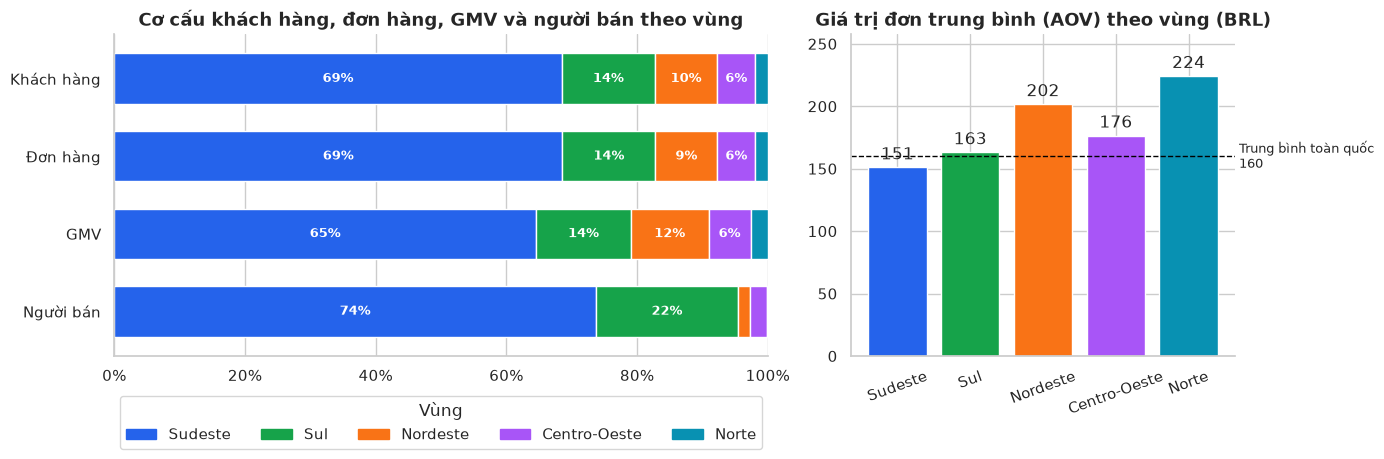

              orders  customers     revenue    aov freight_ratio  sellers
region                                                                   
Sudeste        66423      64178  10030039.0  151.0         15.1%     2244
Sul            13774      13341   2246217.0  163.1         17.6%      659
Nordeste        9176       8930   1849784.0  201.6         21.7%       55
Centro-Oeste    5631       5456    993569.0  176.4         17.6%       79
Norte           1813       1759    406397.0  224.2         22.7%        5

             Khách hàng Đơn hàng    GMV Người bán
region                                           
Sudeste           68.5%    68.6%  64.6%     73.8%
Sul               14.2%    14.2%  14.5%     21.7%
Nordeste           9.5%     9.5%  11.9%      1.8%
Centro-Oeste       5.8%     5.8%   6.4%      2.6%
Norte              1.9%     1.9%   2.6%      0.2%


In [6]:
reg = q(f"SELECT customer_region AS region, {BIZ_METRICS} FROM sales GROUP BY 1")
sel = q("""SELECT r.region, count(DISTINCT s.seller_key) AS sellers
           FROM dim_seller s JOIN state_ref r ON r.state = s.state
           WHERE s.seller_key IN (SELECT DISTINCT seller_key FROM item_ps) GROUP BY 1""")
reg = reg.merge(sel, on="region", how="left").fillna({"sellers": 0}).set_index("region").reindex(REGIONS)
share = pd.DataFrame({m: reg[c] / reg[c].sum() for m, c in
                      [("Khách hàng", "customers"), ("Đơn hàng", "orders"), ("GMV", "revenue"), ("Người bán", "sellers")]})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.7, 1]})
share.T.plot(kind="barh", stacked=True, ax=ax1, color=region_colors(), width=0.65, legend=False)
for c in ax1.containers:
    ax1.bar_label(c, labels=[f"{w:.0%}" if w >= 0.04 else "" for w in c.datavalues], label_type="center",
                  color="white", fontsize=9, fontweight="bold")
pct_axis(ax1, "x"); ax1.invert_yaxis(); ax1.set_xlim(0, 1)
ax1.set_title("Cơ cấu khách hàng, đơn hàng, GMV và người bán theo vùng")
region_legend(ax1, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=5)
bars = ax2.bar(REGIONS, reg.aov, color=region_colors())
ax2.bar_label(bars, labels=[f"{v:,.0f}" for v in reg.aov], padding=3)
ax2.axhline(kpi["aov"], color="black", ls="--", lw=1)
ax2.text(1.01, kpi["aov"], f"Trung bình toàn quốc\n{kpi['aov']:.0f}", transform=ax2.get_yaxis_transform(),
         ha="left", va="center", fontsize=9, clip_on=False); ax2.set_ylim(0, reg.aov.max() * 1.15)
ax2.set_title("Giá trị đơn trung bình (AOV) theo vùng (BRL)"); ax2.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

print(reg.assign(revenue=reg.revenue.round(0), aov=reg.aov.round(1),
                 freight_ratio=reg.freight_ratio.map("{:.1%}".format)).to_string())
print(); print(share.map("{:.1%}".format).to_string())

> **🔎 Kết quả chính**
> - **Lệch cung – cầu rõ rệt**: Nordeste có 9,5% khách và **11,9% doanh thu** nhưng chỉ **1,8% người bán** (55 người). Norte có 1,9% khách, chỉ **5 người bán**.
>   Ngược lại, Sul có 14,3% khách nhưng 21,6% người bán; Sudeste có 68,5% khách và 73,9% người bán.
> - **AOV tăng dần theo khoảng cách** tới trung tâm: Sudeste 151 BRL → Sul 163 → Centro-Oeste 177 → Nordeste 201 → **Norte 223 BRL**.
>   Vì vậy tỷ trọng doanh thu của các vùng xa cao hơn tỷ trọng số đơn.

## 4. Giá trị khách hàng theo bang
*Câu hỏi: "Ở đâu khách chi nhiều hơn cho mỗi đơn? Bang đông khách có phải bang chi tiêu cao?"*

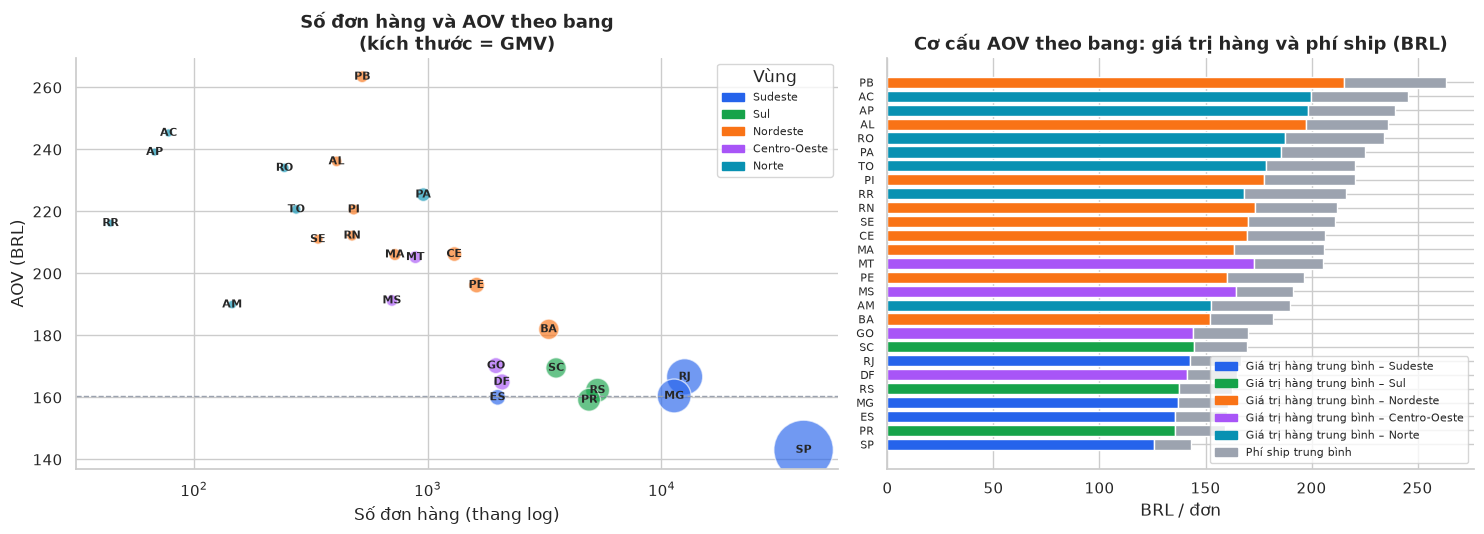

Tương quan log(số đơn) và AOV giữa các bang: -0.80
state       region  orders    aov  avg_product_value  avg_freight  rev_per_customer  orders_per_customer
   PB     Nordeste     525 263.45             215.55        47.90            271.74                 1.03
   AC        Norte      78 245.32             199.70        45.62            258.58                 1.05
   AP        Norte      68 239.16             198.15        41.01            242.73                 1.01
   AL     Nordeste     408 236.14             197.34        38.80            243.30                 1.03
   RO        Norte     244 234.05             187.67        46.38            246.16                 1.05
   PA        Norte     959 225.42             185.46        39.97            231.46                 1.03
   TO        Norte     274 220.66             178.71        41.95            225.60                 1.02
   PI     Nordeste     483 220.62             177.55        43.07            226.24                 1.03
   R

In [7]:
cust = q("""SELECT customer_state AS state, arbitrary(customer_region) AS region,
                   sum(gmv) / count(DISTINCT customer_unique_id) AS rev_per_customer,
                   CAST(count(*) AS DOUBLE) / count(DISTINCT customer_unique_id) AS orders_per_customer,
                   avg(product_value) AS avg_product_value, avg(freight_value) AS avg_freight
            FROM sales GROUP BY 1""")
sv = state.merge(cust, on=["state", "region"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})
ax1.scatter(sv.orders, sv.aov, s=sv.revenue / sv.revenue.max() * 1800 + 30,
            c=sv.region.map(REGION_COLORS), alpha=0.65, edgecolor="white")
for _, r in sv.iterrows():
    ax1.annotate(r.state, (r.orders, r.aov), ha="center", va="center", fontsize=8, fontweight="bold")
ax1.set_xscale("log"); ax1.axhline(kpi["aov"], color=C_GREY, ls="--", lw=1)
ax1.set_xlabel("Số đơn hàng (thang log)"); ax1.set_ylabel("AOV (BRL)")
ax1.set_title("Số đơn hàng và AOV theo bang\n(kích thước = GMV)"); region_legend(ax1, loc="upper right", fontsize=8)

so = sv.sort_values("aov")
ax2.barh(so.state, so.avg_product_value, color=so.region.map(REGION_COLORS))
ax2.barh(so.state, so.avg_freight, left=so.avg_product_value, color=C_GREY)
ax2.set_title("Cơ cấu AOV theo bang: giá trị hàng và phí ship (BRL)"); ax2.set_xlabel("BRL / đơn")
# Chú thích: phần giá trị hàng trung bình tô theo màu vùng, phần phí ship trung bình màu xám
region_legend(ax2, label_fmt="Giá trị hàng trung bình – {}", extra=[("Phí ship trung bình", C_GREY)], title=None,
              loc="lower right", fontsize=8)
ax2.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()

corr = np.corrcoef(np.log(sv.orders), sv.aov)[0, 1]
print(f"Tương quan log(số đơn) và AOV giữa các bang: {corr:.2f}")
print(sv.sort_values("aov", ascending=False)[["state", "region", "orders", "aov", "avg_product_value", "avg_freight",
                                              "rev_per_customer", "orders_per_customer"]].round(2).to_string(index=False))

> **🔎 Kết quả chính**
> - Bang càng ít đơn thì AOV càng cao (tương quan **−0,81** giữa log số đơn và AOV). PB (264 BRL), AC, AP, AL, RO có AOV cao nhất; **SP thấp nhất (143 BRL)**.
> - Chênh lệch **không chỉ do phí ship**: giá trị hàng TB ở PB là 216 BRL so với 126 BRL ở SP. Khách ở vùng xa có xu hướng mua online các món giá trị cao,
>   còn hàng giá trị thấp thì không đáng trả phí ship.
> - Số đơn / khách gần như bằng nhau ở mọi bang (1,01–1,05). Khác biệt giá trị khách hàng giữa các bang đến từ **giá trị mỗi đơn**, không phải tần suất mua.

## 5. Tăng trưởng theo vùng và bang
*Câu hỏi: "Vùng/bang nào đang tăng nhanh? Vùng nào thật sự tạo ra phần doanh thu tăng thêm?"*

- **% tăng trưởng** = GMV kỳ này so với cùng kỳ năm trước.
- **Đóng góp vào tăng trưởng** = GMV tăng thêm của vùng / GMV tăng thêm của toàn sàn. So với **tỷ trọng cùng kỳ năm trước**: vùng có đóng góp > tỷ trọng đang **giành thêm thị phần**.
- Tổng GMV theo tháng xem `executive_overview` §2; ở đây chỉ vẽ **tỷ trọng** từng vùng theo tháng.

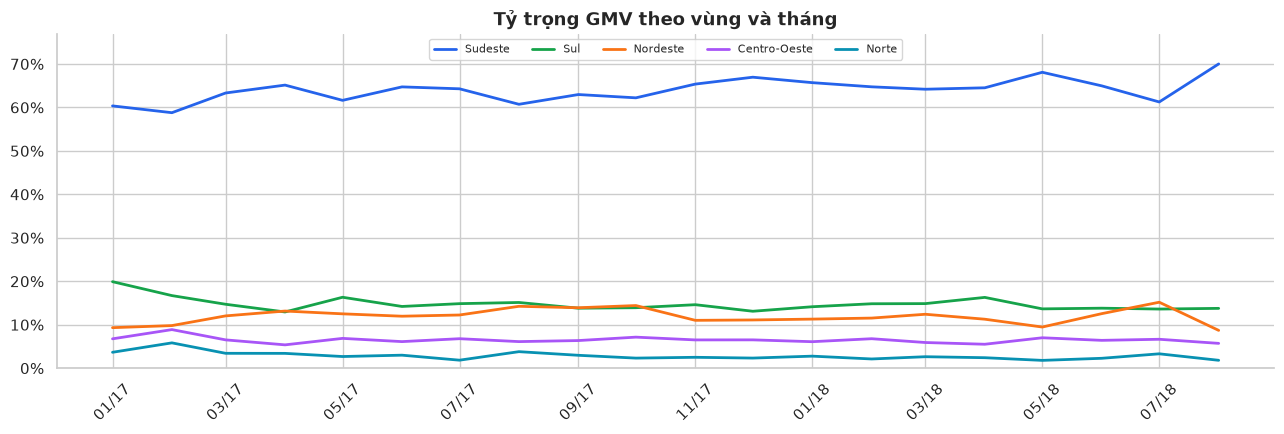

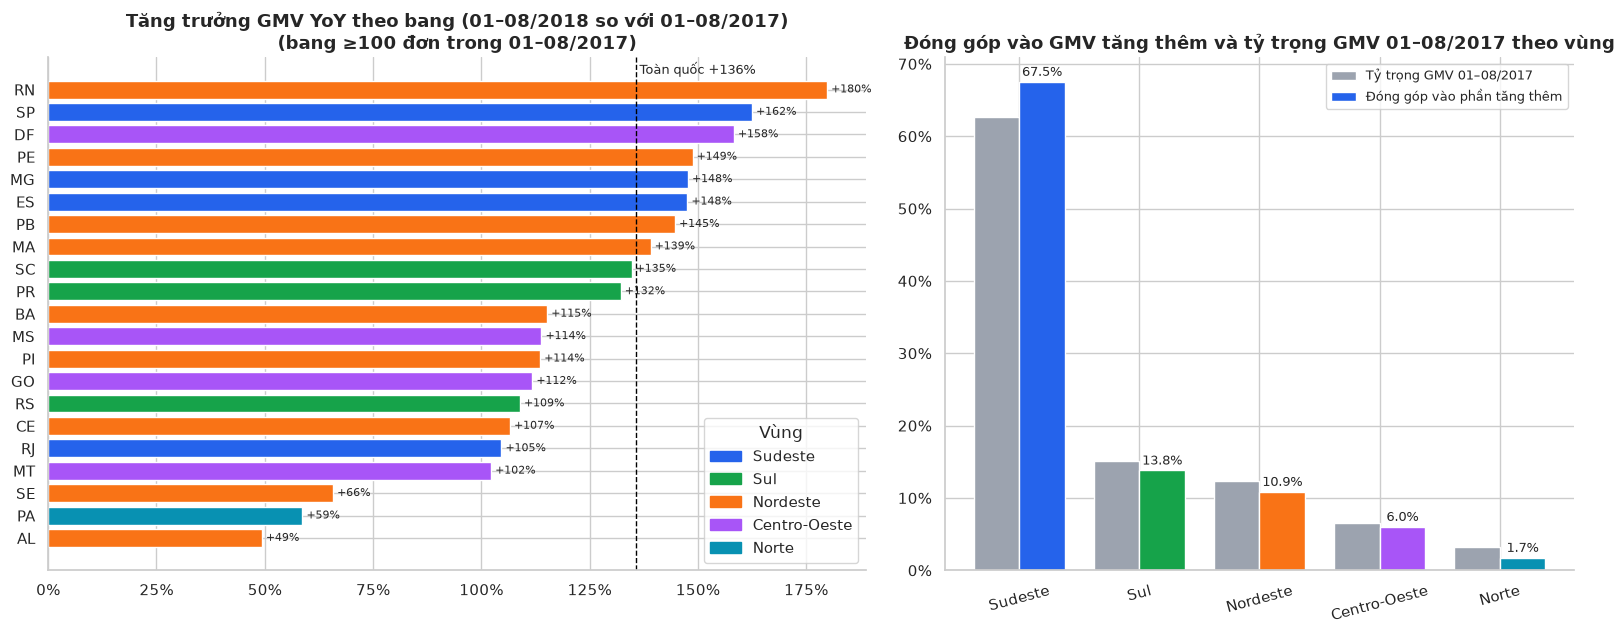

Tăng trưởng toàn quốc: +135.6%
               rev_prev    rev_cur   growth contrib share_prev
region                                                        
Sudeste       2233216.0  5497916.0  +146.2%   67.5%      62.7%
Sul            540257.0  1208320.0  +123.7%   13.8%      15.2%
Nordeste       441568.0   966787.0  +118.9%   10.9%      12.4%
Centro-Oeste   233510.0   524846.0  +124.8%    6.0%       6.6%
Norte          116037.0   200560.0   +72.8%    1.7%       3.3%

state       region  rev_prev   rev_cur  growth
   RN     Nordeste   20069.0   56156.0 +179.8%
   SP      Sudeste 1257467.0 3300535.0 +162.5%
   DF Centro-Oeste   72885.0  188257.0 +158.3%
   PE     Nordeste   67114.0  166950.0 +148.8%
   MG      Sudeste  394945.0  978262.0 +147.7%
   ES      Sudeste   71399.0  176749.0 +147.6%
   PB     Nordeste   30990.0   75833.0 +144.7%
   MA     Nordeste   30763.0   73544.0 +139.1%
   SC          Sul  140144.0  328895.0 +134.7%
   PR          Sul  187465.0  435211.0 +132.2%
   BA     

In [8]:
monthly = q(f"""SELECT purchase_month, customer_region AS region, sum(gmv) AS revenue
                FROM sales WHERE {P.in_period} GROUP BY 1, 2""")
piv = monthly.pivot(index="purchase_month", columns="region", values="revenue")[REGIONS].fillna(0)
mix = piv.div(piv.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(13, 4.5))
for r in REGIONS:
    ax.plot(mix.index, mix[r], color=REGION_COLORS[r], lw=2, label=r)
pct_axis(ax); ax.set_ylim(0, min(1, mix.max().max() * 1.1)); ax.legend(fontsize=8, ncol=5, loc="upper center")
month_axis(ax); ax.set_title("Tỷ trọng GMV theo vùng và tháng")
plt.tight_layout(); plt.show()

# Theo bang: GMV và số đơn cùng kỳ năm trước (prev) / kỳ này (cur)
yoy = q(f"""SELECT customer_state AS state, arbitrary(customer_region) AS region,
                   sum(gmv) FILTER (WHERE {P.prev}) AS rev_prev, sum(gmv) FILTER (WHERE {P.cur}) AS rev_cur,
                   count(*) FILTER (WHERE {P.prev}) AS ord_prev, count(*) FILTER (WHERE {P.cur}) AS ord_cur
            FROM sales WHERE ({P.prev}) OR ({P.cur}) GROUP BY 1""")
yoy["growth"] = yoy.rev_cur / yoy.rev_prev - 1
nat_growth = yoy.rev_cur.sum() / yoy.rev_prev.sum() - 1
yoy_reg = yoy.groupby("region")[["rev_prev", "rev_cur"]].sum().reindex(REGIONS)
yoy_reg["growth"] = yoy_reg.rev_cur / yoy_reg.rev_prev - 1
yoy_reg["contrib"] = (yoy_reg.rev_cur - yoy_reg.rev_prev) / (yoy.rev_cur.sum() - yoy.rev_prev.sum())
yoy_reg["share_prev"] = yoy_reg.rev_prev / yoy.rev_prev.sum()

ys = yoy[yoy.ord_prev >= MIN_STATE_ORDERS_PREV].sort_values("growth")   # bỏ bang quá nhỏ để % tăng trưởng không bị nhiễu
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.3, 1]})
bars = ax1.barh(ys.state, ys.growth, color=ys.region.map(REGION_COLORS))
ax1.bar_label(bars, labels=[f"{v:+.0%}" for v in ys.growth], padding=3, fontsize=8)
ax1.axvline(nat_growth, color="black", ls="--", lw=1); ax1.text(nat_growth, len(ys) - 0.3, f" Toàn quốc {nat_growth:+.0%}", fontsize=9)
pct_axis(ax1, "x"); region_legend(ax1, loc="lower right")
ax1.set_title(f"Tăng trưởng GMV YoY theo bang ({P.label_cur} so với {P.label_prev})\n"
              f"(bang ≥{MIN_STATE_ORDERS_PREV} đơn trong {P.label_prev})")
x = np.arange(len(REGIONS)); w = 0.38
ax2.bar(x - w/2, yoy_reg.share_prev, w, color=C_GREY, label=f"Tỷ trọng GMV {P.label_prev}")
contrib_bars = ax2.bar(x + w/2, yoy_reg.contrib, w, color=region_colors(), label="Đóng góp vào phần tăng thêm")
ax2.bar_label(contrib_bars, labels=[f"{v:.1%}" for v in yoy_reg.contrib], padding=2, fontsize=9)
ax2.set_xticks(x, REGIONS, rotation=15); pct_axis(ax2); ax2.legend(fontsize=9)
ax2.set_title(f"Đóng góp vào GMV tăng thêm và tỷ trọng GMV {P.label_prev} theo vùng")
plt.tight_layout(); plt.show()

print(f"Tăng trưởng toàn quốc: {nat_growth:+.1%}")
print(yoy_reg.assign(growth=yoy_reg.growth.map("{:+.1%}".format), contrib=yoy_reg.contrib.map("{:.1%}".format),
                     share_prev=yoy_reg.share_prev.map("{:.1%}".format)).round(0).to_string())
print(); print(ys.sort_values("growth", ascending=False)[["state", "region", "rev_prev", "rev_cur", "growth"]]
               .assign(growth=lambda d: d.growth.map("{:+.1%}".format)).round(0).to_string(index=False))

> **🔎 Kết quả chính**
> - Doanh thu 01–08/2018 tăng **+140%** so với cùng kỳ 2017.
> - **Sudeste tăng nhanh nhất (+151%)**, tiếp theo Centro-Oeste (+133%), Sul (+129%), Nordeste (+123%), **Norte chậm nhất (+76%)**. Tỷ trọng các vùng gần như không đổi theo tháng (Sudeste ~60–70%): sàn tăng nhờ thị trường lõi, **chưa mở rộng được ra vùng mới**.
> - **Sudeste tạo 67,3% phần GMV tăng thêm**, cao hơn tỷ trọng sẵn có (62,7%); các vùng khác đều đóng góp thấp hơn tỷ trọng, rõ nhất Norte (1,7% so với 3,2%).
> - Theo bang: RN (+183%), DF (+170%), SP (+167%) dẫn đầu; **AL (+51%), PA (+61%), SE (+73%)** chậm nhất. **RJ** lớn thứ 2 nhưng chỉ +109%, thấp nhất trong các bang lớn.

## 6. Thành phố trọng điểm & bản đồ phân bố khách hàng
*Câu hỏi: "Thành phố nào là thị trường lớn nhất? Khách hàng và người bán tập trung ở đâu trên bản đồ?"*

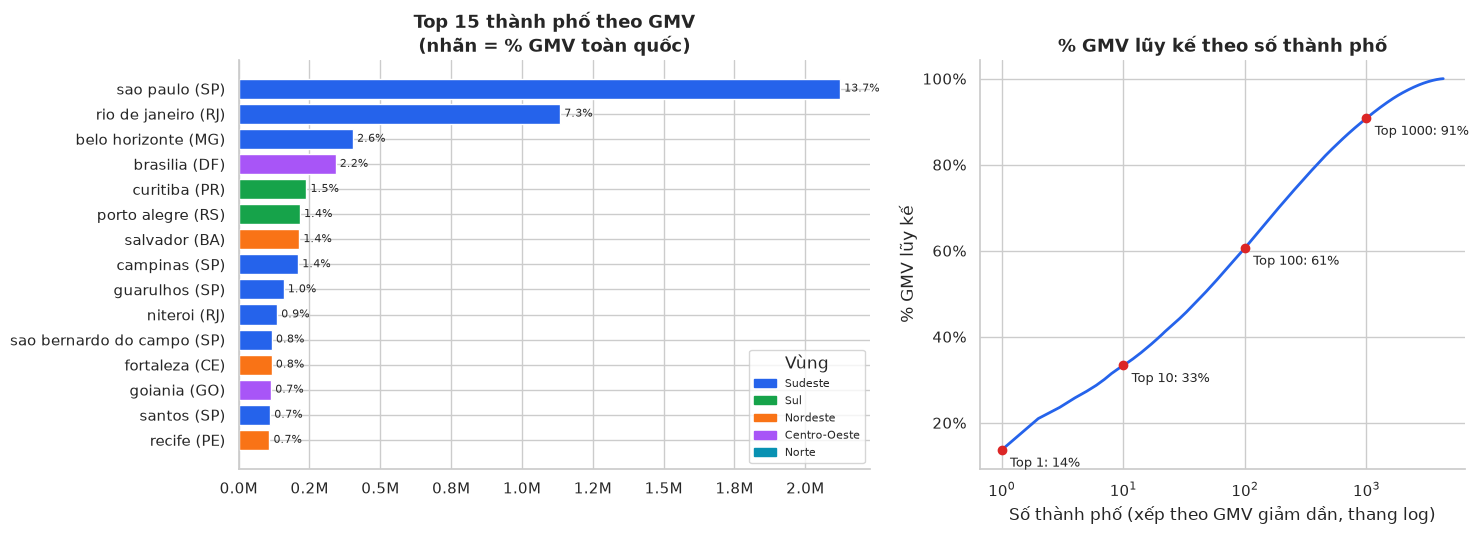

                      city       region  orders  customers   revenue   aov rev_share
            sao paulo (SP)      Sudeste   15067      14536 2122858.0 140.9     13.7%
       rio de janeiro (RJ)      Sudeste    6728       6467 1134722.0 168.7      7.3%
       belo horizonte (MG)      Sudeste    2691       2596  403425.0 149.9      2.6%
             brasilia (DF) Centro-Oeste    2071       2010  342353.0 165.3      2.2%
             curitiba (PR)          Sul    1479       1422  238981.0 161.6      1.5%
         porto alegre (RS)          Sul    1348       1296  216137.0 160.3      1.4%
             salvador (BA)     Nordeste    1215       1180  213865.0 176.0      1.4%
             campinas (SP)      Sudeste    1406       1364  209947.0 149.3      1.4%
            guarulhos (SP)      Sudeste    1143       1110  158996.0 139.1      1.0%
              niteroi (RJ)      Sudeste     830        790  135535.0 163.3      0.9%
sao bernardo do campo (SP)      Sudeste     910        880  11706

In [9]:
city = q(f"""SELECT customer_city || ' (' || customer_state || ')' AS city, arbitrary(customer_region) AS region, {BIZ_METRICS}
             FROM sales GROUP BY customer_city, customer_state ORDER BY revenue DESC""")
city["rev_share"] = city.revenue / city.revenue.sum()
top = city.head(15).iloc[::-1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})
bars = ax1.barh(top.city, top.revenue, color=top.region.map(REGION_COLORS))
ax1.bar_label(bars, labels=[f"{s:.1%}" for s in top.rev_share], padding=3, fontsize=8)
brl_axis(ax1, "x"); ax1.set_title("Top 15 thành phố theo GMV\n(nhãn = % GMV toàn quốc)")
region_legend(ax1, loc="lower right", fontsize=8)
n_cities = np.arange(1, len(city) + 1)
ax2.plot(n_cities, city.rev_share.cumsum(), color=C_MAIN, lw=2)
ax2.set_xscale("log"); pct_axis(ax2); ax2.set_xlabel("Số thành phố (xếp theo GMV giảm dần, thang log)"); ax2.set_ylabel("% GMV lũy kế")
for k in CITY_MARKS:
    v = city.rev_share.head(k).sum()
    ax2.scatter(k, v, color=C_BAD, zorder=3); ax2.annotate(f"Top {k}: {v:.0%}", (k, v), xytext=(6, -12), textcoords="offset points", fontsize=9)
ax2.set_title("% GMV lũy kế theo số thành phố")
plt.tight_layout(); plt.show()
print(city.head(15).assign(revenue=lambda d: d.revenue.round(0), aov=lambda d: d.aov.round(1),
                           rev_share=lambda d: d.rev_share.map("{:.1%}".format))
      .drop(columns="freight_ratio").to_string(index=False))

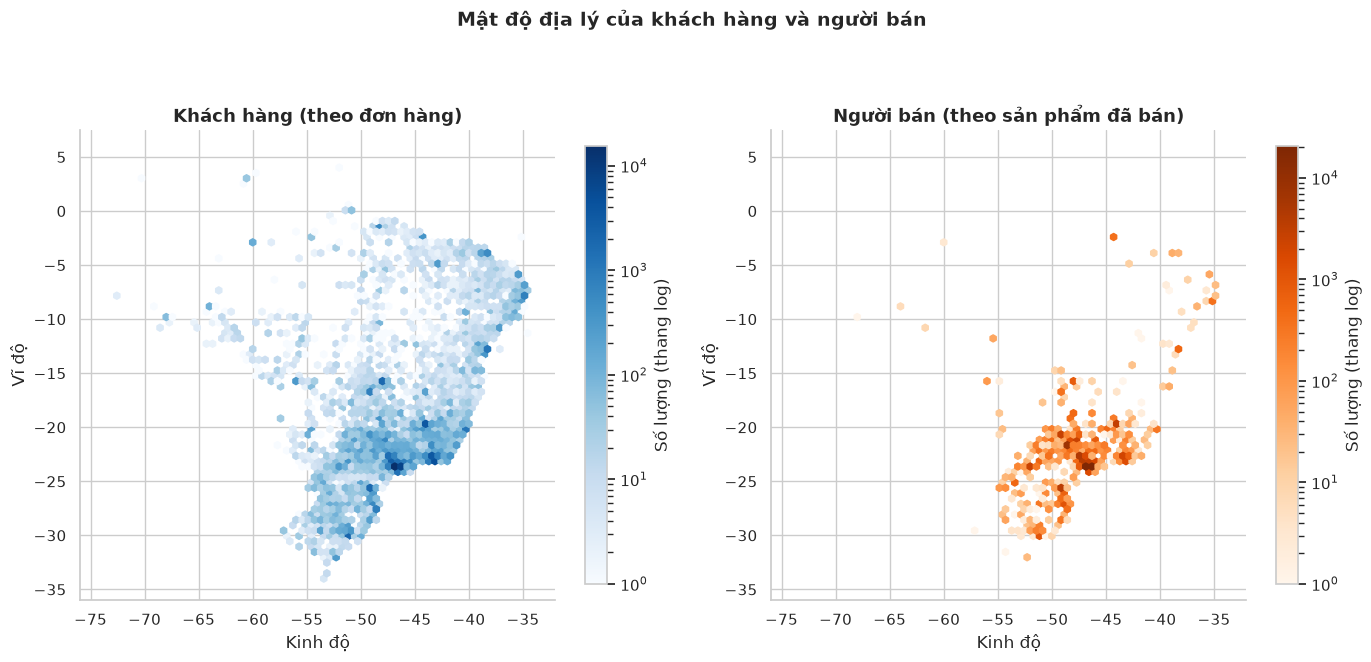

In [10]:
# Bản đồ mật độ: khách hàng (theo đơn hợp lệ) và người bán (theo dòng sản phẩm đã bán)
lng_min, lng_max, lat_min, lat_max = BR_BOX
IN_BR = f"latitude BETWEEN {lat_min} AND {lat_max} AND longitude BETWEEN {lng_min} AND {lng_max}"
cust_pts = q(f"SELECT longitude, latitude FROM sales WHERE {IN_BR}")
sell_pts = q(f"""SELECT g.longitude, g.latitude FROM item_ps i JOIN dim_seller s ON s.seller_key = i.seller_key
                 JOIN dim_geolocation g ON g.geolocation_key = s.geolocation_key WHERE {IN_BR}""")

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, pts, title, cmap in [(axes[0], cust_pts, "Khách hàng (theo đơn hàng)", "Blues"),
                             (axes[1], sell_pts, "Người bán (theo sản phẩm đã bán)", "Oranges")]:
    hb = ax.hexbin(pts.longitude, pts.latitude, gridsize=70, bins="log", cmap=cmap, mincnt=1, extent=BR_BOX)
    ax.set_title(title); ax.set_aspect("equal"); ax.set_xlabel("Kinh độ"); ax.set_ylabel("Vĩ độ")
    fig.colorbar(hb, ax=ax, shrink=0.7, label="Số lượng (thang log)")
plt.suptitle("Mật độ địa lý của khách hàng và người bán", fontweight="bold", fontsize=14)
plt.tight_layout(); plt.show()

> **🔎 Kết quả chính**
> - Thành phố **São Paulo một mình chiếm 13,7%** doanh thu, Rio de Janeiro 7,3%. Top 10 thành phố chiếm 33%, top 100 chiếm 61%, phần còn lại rải ở hơn 4.000 thành phố nhỏ.
> - Khách hàng trải dọc bờ biển phía Đông và lan vào nội địa, còn **người bán dồn vào khu SP – PR – SC** (3 bang duy nhất có cung lớn hơn cầu, xem phần 7).

## 7. Cung – cầu: người bán có ở gần khách hàng?
*Câu hỏi: "Khách ở mỗi vùng mua hàng từ người bán ở đâu? Vùng nào có nhu cầu nhưng thiếu người bán tại chỗ?"*

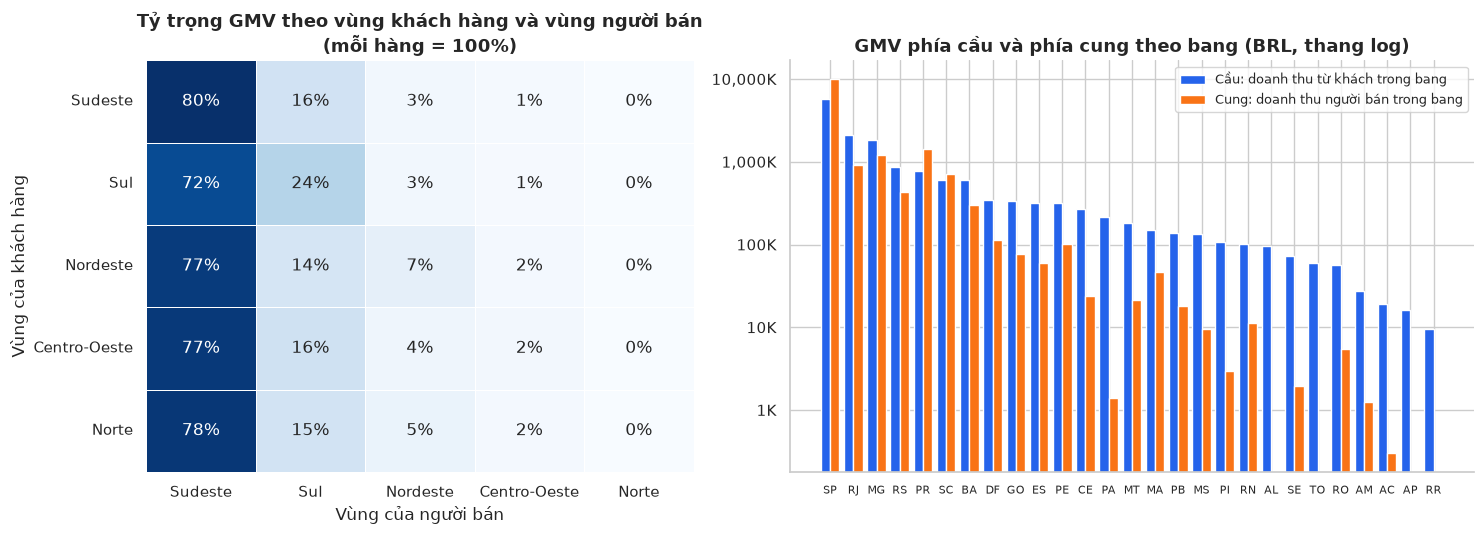

seller_region   Sudeste    Sul Nordeste Centro-Oeste Norte
customer_region                                           
Sudeste           80.5%  15.5%     2.6%         1.4%  0.1%
Sul               72.2%  24.2%     2.5%         1.0%  0.0%
Nordeste          76.7%  14.1%     7.4%         1.7%  0.1%
Centro-Oeste      77.5%  16.4%     3.7%         2.4%  0.0%
Norte             78.1%  15.2%     5.1%         1.7%  0.0%

state       region    demand     supply  sellers local_share  supply_demand
   SP      Sudeste 5799314.0 10021215.0     1813       69.1%           1.73
   RJ      Sudeste 2093296.0   921584.0      170        9.5%           0.44
   MG      Sudeste 1818633.0  1196946.0      239       11.4%           0.66
   RS          Sul  865187.0   429881.0      129        7.1%           0.50
   PR          Sul  780435.0  1435730.0      344       14.8%           1.84
   SC          Sul  600595.0   718981.0      186        8.5%           1.20
   BA     Nordeste  600148.0   304022.0       19      

In [11]:
flow = q("""SELECT customer_region, seller_region, sum(gmv) AS revenue FROM item_ps
            WHERE seller_region IS NOT NULL GROUP BY 1, 2""")
mat = flow.pivot(index="customer_region", columns="seller_region", values="revenue").reindex(index=REGIONS, columns=REGIONS).fillna(0)
mat_pct = mat.div(mat.sum(axis=1), axis=0)

sd = q("""WITH d AS (SELECT customer_state AS state, sum(gmv) AS demand,
                            sum(gmv) FILTER (WHERE seller_state = customer_state) AS local_rev FROM item_ps GROUP BY 1),
                s AS (SELECT seller_state AS state, sum(gmv) AS supply, count(DISTINCT seller_key) AS sellers FROM item_ps GROUP BY 1)
           SELECT d.state, r.region, d.demand, coalesce(d.local_rev, 0) AS local_rev,
                  coalesce(s.supply, 0) AS supply, coalesce(s.sellers, 0) AS sellers
           FROM d JOIN state_ref r ON r.state = d.state LEFT JOIN s ON s.state = d.state""")
sd["local_share"] = sd.local_rev / sd.demand
sd["supply_demand"] = sd.supply / sd.demand            # >1: bang "xuất" hàng; <1: bang "nhập" hàng
sd = sd.sort_values("demand", ascending=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1.25]})
sns.heatmap(mat_pct, annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=ax1, linewidths=0.5)
ax1.set_xlabel("Vùng của người bán"); ax1.set_ylabel("Vùng của khách hàng"); ax1.tick_params(axis="y", rotation=0)
ax1.set_title("Tỷ trọng GMV theo vùng khách hàng và vùng người bán\n(mỗi hàng = 100%)")
x = np.arange(len(sd)); w = 0.4
ax2.bar(x - w/2, sd.demand, w, color=C_MAIN, label="Cầu: doanh thu từ khách trong bang")
ax2.bar(x + w/2, sd.supply, w, color=C_ORANGE, label="Cung: doanh thu người bán trong bang")
ax2.set_yscale("log"); ax2.set_xticks(x, sd.state, fontsize=8); ax2.legend(fontsize=9)
ax2.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1e3:,.0f}K"))
ax2.set_title("GMV phía cầu và phía cung theo bang (BRL, thang log)")
plt.tight_layout(); plt.show()

print(mat_pct.map("{:.1%}".format).to_string()); print()
print(sd.assign(demand=sd.demand.round(0), supply=sd.supply.round(0), local_share=sd.local_share.map("{:.1%}".format),
                supply_demand=sd.supply_demand.round(2)).drop(columns="local_rev").to_string(index=False))

> **🔎 Kết quả chính**
> - Ở **mọi vùng**, 72–80% doanh thu đến từ người bán vùng Sudeste. Khách Nordeste chỉ mua **7,4%** từ người bán trong vùng; khách Norte gần như **0%**.
> - Chỉ **SP (cung/cầu = 1,73), PR (1,83) và SC (1,20)** là bang "xuất" hàng; mọi bang khác đều phụ thuộc vào hàng từ nơi khác.
>   **AL, TO, AP, RR không có người bán nào**; PA (217 nghìn BRL nhu cầu) chỉ có 1 người bán.
> - **RJ** là điểm đáng chú ý: thị trường lớn thứ 2 (2,1 triệu BRL) nhưng chỉ **9,5%** doanh thu do người bán trong bang phục vụ.
>   Kết hợp với tăng trưởng thấp ở phần 5, RJ là ứng viên ưu tiên để tuyển người bán / đặt kho.

## 8. Chi phí phục vụ: phí ship theo khu vực
*Câu hỏi: "Phục vụ khách ở vùng xa tốn hơn bao nhiêu phí ship? Có liên quan đến việc thiếu người bán tại chỗ không?"*

Phần này chỉ nhìn **chi phí (phí ship / giá trị hàng)**. Thời gian giao, trễ hạn và mức hài lòng theo bang xem `customer_experience` §5.
Trục X của biểu đồ bên phải lấy `local_share` từ phần 7: % nhu cầu của bang được người bán **cùng bang** phục vụ.

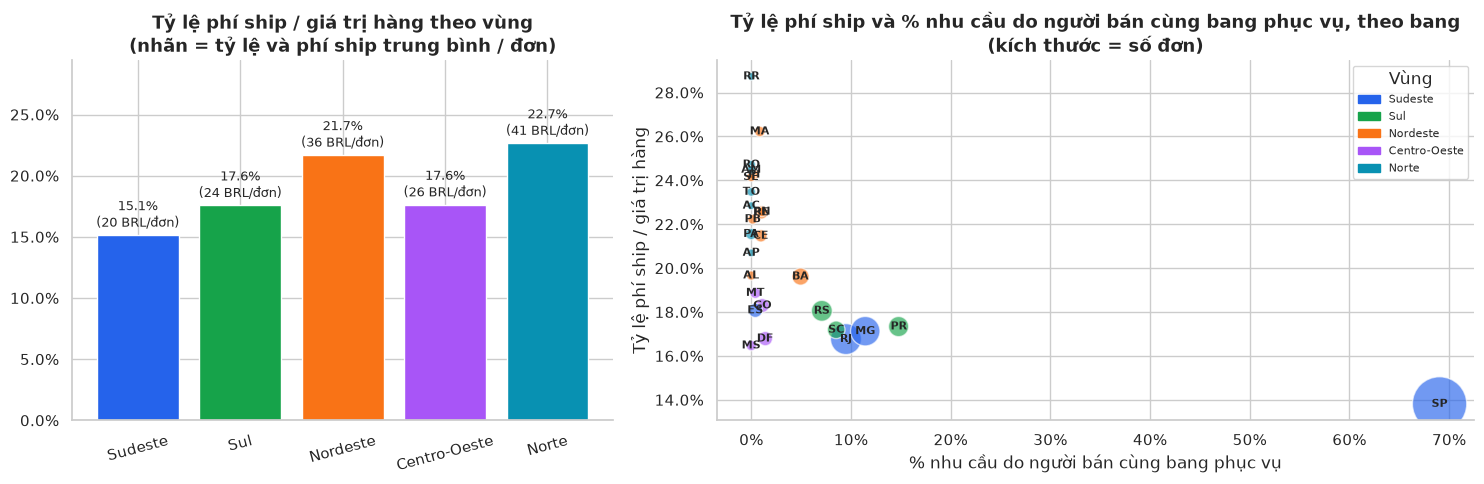

Tương quan theo bang giữa % phục vụ tại chỗ và phí ship / giá trị hàng: -0.52
              avg_freight  freight_ratio
region                                  
Sudeste            19.859          0.151
Sul                24.374          0.176
Nordeste           35.929          0.217
Centro-Oeste       26.439          0.176
Norte              41.402          0.227

state       region  orders  local_share  avg_freight  freight_ratio
   RR        Norte      44        0.000       48.257          0.287
   MA     Nordeste     725        0.009       42.816          0.262
   RO        Norte     244        0.000       46.378          0.247
   AM        Norte     146        0.000       37.356          0.245
   PI     Nordeste     483        0.003       43.068          0.243
   SE     Nordeste     340        0.000       41.046          0.241
   TO        Norte     274        0.000       41.945          0.235
   AC        Norte      78        0.000       45.617          0.228
   RN     Nordeste    

In [12]:
cost_reg = q("""SELECT customer_region AS region, avg(freight_value) AS avg_freight,
                       sum(freight_value) / sum(product_value) AS freight_ratio
                FROM sales GROUP BY 1""").set_index("region").reindex(REGIONS)
cost = sd.merge(q("""SELECT customer_state AS state, count(*) AS orders, avg(freight_value) AS avg_freight,
                              sum(freight_value) / sum(product_value) AS freight_ratio
                       FROM sales GROUP BY 1"""), on="state")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.4]})
x = np.arange(len(REGIONS))
b = ax1.bar(x, cost_reg.freight_ratio, color=region_colors())
ax1.bar_label(b, labels=[f"{v:.1%}\n({f:.0f} BRL/đơn)" for v, f in zip(cost_reg.freight_ratio, cost_reg.avg_freight)],
              padding=3, fontsize=9)
ax1.set_xticks(x, REGIONS, rotation=15); pct_axis(ax1); ax1.set_ylim(0, cost_reg.freight_ratio.max() * 1.3)
ax1.set_title("Tỷ lệ phí ship / giá trị hàng theo vùng\n(nhãn = tỷ lệ và phí ship trung bình / đơn)")
ax2.scatter(cost.local_share, cost.freight_ratio, s=cost.orders / cost.orders.max() * 1500 + 30,
            c=cost.region.map(REGION_COLORS), alpha=0.65, edgecolor="white")
for _, r in cost.iterrows():
    ax2.annotate(r.state, (r.local_share, r.freight_ratio), ha="center", va="center", fontsize=8, fontweight="bold")
pct_axis(ax2); pct_axis(ax2, "x"); ax2.set_xlabel("% nhu cầu do người bán cùng bang phục vụ"); ax2.set_ylabel("Tỷ lệ phí ship / giá trị hàng")
ax2.set_title("Tỷ lệ phí ship và % nhu cầu do người bán cùng bang phục vụ, theo bang\n(kích thước = số đơn)"); region_legend(ax2, loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

print(f"Tương quan theo bang giữa % phục vụ tại chỗ và phí ship / giá trị hàng: {cost.local_share.corr(cost.freight_ratio):+.2f}")
print(cost_reg.round(3).to_string()); print()
print(cost.sort_values("freight_ratio", ascending=False)[["state", "region", "orders", "local_share", "avg_freight", "freight_ratio"]]
      .round(3).to_string(index=False))

> **🔎 Kết quả chính**
> - Phục vụ vùng xa đắt hơn rõ rệt: phí ship / giá trị hàng **15,2%** (≈ 20 BRL/đơn) ở Sudeste so với **21,7%** (≈ 36 BRL) ở Nordeste và **22,7%** (≈ 41 BRL) ở Norte.
> - Gần như **mọi bang ngoài SP** chỉ được người bán cùng bang phục vụ dưới 15% nhu cầu; SP là 69% và có phí ship thấp nhất (13,8%).
>   Các bang phí ship cao nhất (RR 28,5%, MA 26,4%, RO, AM, PI, SE ~24–25%) đều có **0–1%** nhu cầu được phục vụ tại chỗ.
> - Tương quan theo bang giữa % phục vụ tại chỗ và phí ship là **−0,52** (chủ yếu do SP): chi phí cao và thiếu cung tại chỗ đi cùng nhau ở Nordeste/Norte.

## 9. Cơ cấu ngành hàng theo vùng
*Câu hỏi: "Mỗi vùng mua gì nhiều hơn hay ít hơn so với cả nước?"*

**Chỉ số tập trung (LQ)** = tỷ trọng ngành trong doanh thu của vùng / tỷ trọng ngành trong doanh thu cả nước.
LQ > 1: vùng đó mua ngành này nhiều hơn mức trung bình cả nước. Tỷ trọng các ngành trên toàn quốc xem `product` §2.

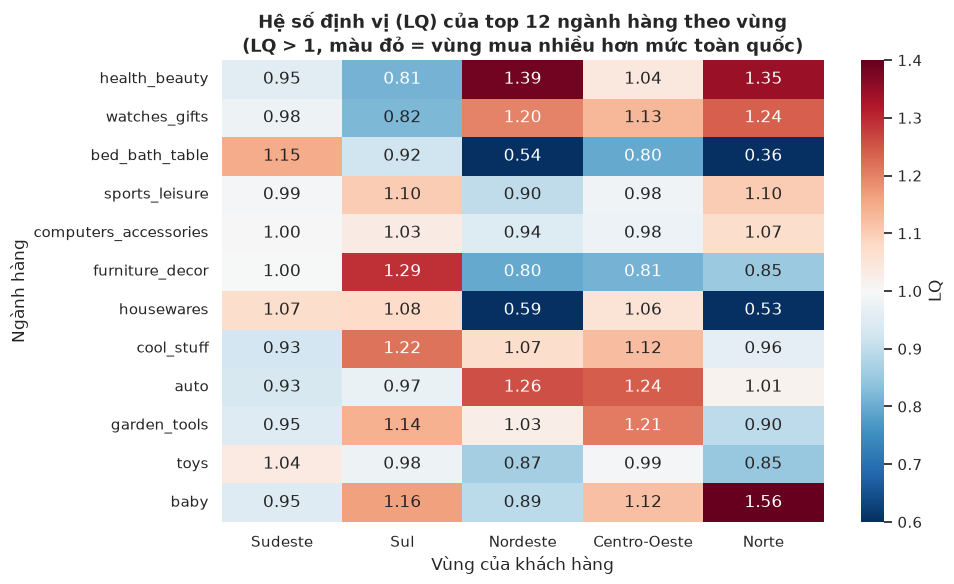

region                Sudeste   Sul Nordeste Centro-Oeste  Norte national
category                                                                 
health_beauty            8.7%  7.4%    12.6%         9.5%  12.2%     9.1%
watches_gifts            8.1%  6.8%     9.9%         9.3%  10.2%     8.3%
bed_bath_table           9.0%  7.2%     4.3%         6.3%   2.9%     7.9%
sports_leisure           7.3%  8.0%     6.6%         7.2%   8.0%     7.3%
computers_accessories    6.7%  6.9%     6.3%         6.5%   7.2%     6.7%
furniture_decor          5.7%  7.4%     4.6%         4.6%   4.9%     5.7%
housewares               5.2%  5.2%     2.9%         5.1%   2.6%     4.9%
cool_stuff               4.2%  5.5%     4.8%         5.1%   4.3%     4.5%
auto                     4.0%  4.2%     5.4%         5.4%   4.4%     4.3%
garden_tools             3.5%  4.2%     3.8%         4.5%   3.3%     3.7%
toys                     3.7%  3.5%     3.1%         3.5%   3.0%     3.5%
baby                     2.9%  3.5%   

In [13]:
cat = q(f"""WITH top AS (SELECT category FROM item_ps GROUP BY 1 ORDER BY sum(gmv) DESC LIMIT {TOP_N})
            SELECT customer_region AS region, category, sum(gmv) AS revenue
            FROM item_ps WHERE category IN (SELECT category FROM top) GROUP BY 1, 2""")
reg_total = q("SELECT customer_region AS region, sum(gmv) AS total FROM item_ps GROUP BY 1").set_index("region").total
nat_total = reg_total.sum()
cp = cat.pivot(index="category", columns="region", values="revenue")[REGIONS].fillna(0)
cp = cp.loc[cp.sum(axis=1).sort_values(ascending=False).index]
share_reg = cp / reg_total[REGIONS]                     # tỷ trọng ngành trong doanh thu từng vùng
share_nat = cp.sum(axis=1) / nat_total
lq = share_reg.div(share_nat, axis=0)

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(lq, annot=True, fmt=".2f", cmap="RdBu_r", center=1, vmin=0.6, vmax=1.4, ax=ax, cbar_kws={"label": "LQ"})
ax.set_ylabel("Ngành hàng"); ax.set_xlabel("Vùng của khách hàng")
ax.set_title(f"Hệ số định vị (LQ) của top {TOP_N} ngành hàng theo vùng\n(LQ > 1, màu đỏ = vùng mua nhiều hơn mức toàn quốc)")
plt.tight_layout(); plt.show()
print(share_reg.map("{:.1%}".format).assign(national=share_nat.map("{:.1%}".format)).to_string())

> **🔎 Kết quả chính**
> - Vùng xa mua nhiều **hàng nhỏ, giá trị cao**: health_beauty (LQ 1,38 ở Nordeste, 1,33 ở Norte), watches_gifts (1,20 / 1,25), baby ở Norte (1,56), auto ở Nordeste/Centro-Oeste (1,26 / 1,23).
> - Ngược lại, **hàng cồng kềnh** gần như không bán được ở vùng xa: bed_bath_table (LQ 0,54 ở Nordeste, 0,36 ở Norte), housewares (0,60 / 0,53).
>   Sul là thị trường của furniture_decor (1,30) và cool_stuff (1,21).
> - Hàm ý: danh mục và khuyến mãi nên được **địa phương hóa**. Muốn bán hàng cồng kềnh ở vùng xa thì phải giải bài toán phí ship / người bán tại chỗ trước.

## 10. Ma trận cơ hội thị trường theo bang
*Câu hỏi: "Bang nào đã khai thác tốt, bang nào còn dư địa và đang tăng nhanh?"*

- **Mức thâm nhập** = số đơn kỳ này / 100.000 dân (dân số ước tính 2018 của IBGE, dữ liệu tham chiếu bên ngoài, đã làm tròn).
- **Tăng trưởng** = doanh thu kỳ này so với cùng kỳ năm trước.
- Chỉ gồm các bang có ≥100 đơn trong cùng kỳ năm trước (21/27 bang). **6 bang nhỏ vùng Norte bị loại** (AM, AC, AP, RR, RO, TO); danh sách được in ra dưới biểu đồ.
- Đường chia 4 góc phần tư = trung vị của các bang. "Tăng chậm" ở đây là **chậm hơn trung vị**, không phải tăng trưởng thấp tuyệt đối.

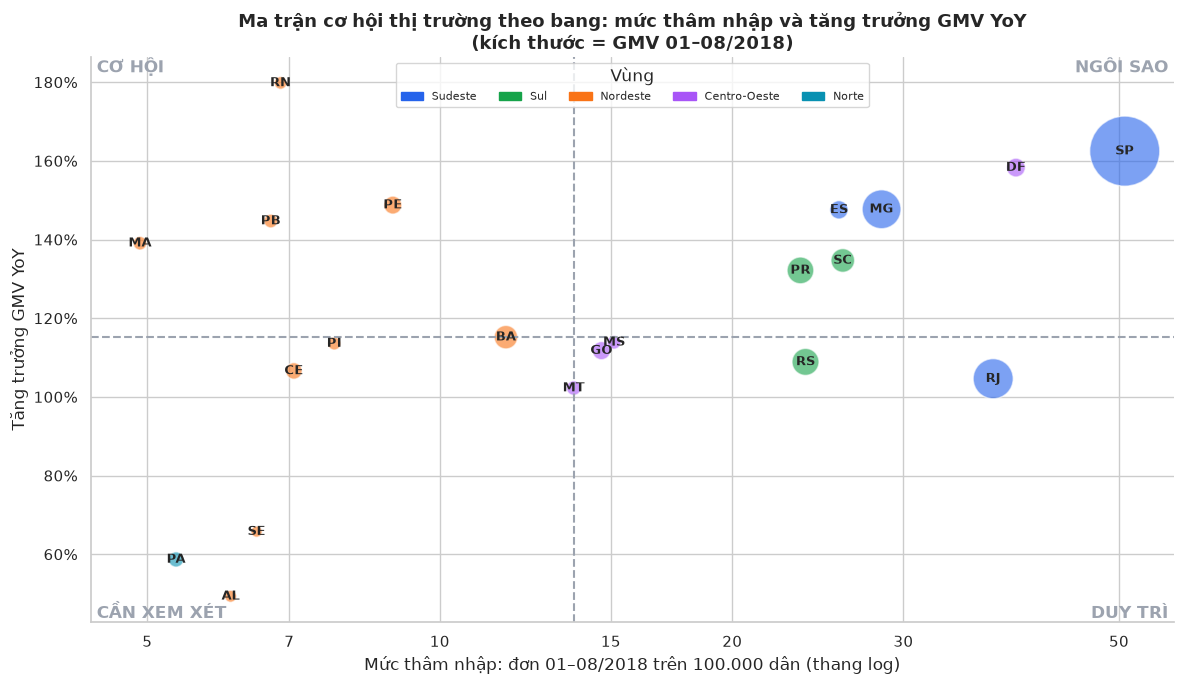

Bị loại do <100 đơn trong 01–08/2017: RR, AP, RO, TO, AC, AM
                                       quadrant state       region  penetration  growth   rev_cur
             Cơ hội: thâm nhập thấp, tăng nhanh    RN     Nordeste          6.9 +179.8%   56156.0
             Cơ hội: thâm nhập thấp, tăng nhanh    PE     Nordeste          8.9 +148.8%  166950.0
             Cơ hội: thâm nhập thấp, tăng nhanh    PB     Nordeste          6.7 +144.7%   75833.0
             Cơ hội: thâm nhập thấp, tăng nhanh    MA     Nordeste          4.9 +139.1%   73544.0
             Cơ hội: thâm nhập thấp, tăng nhanh    BA     Nordeste         11.7 +115.2%  322542.0
Cần xem xét: thâm nhập thấp, tăng dưới trung vị    PI     Nordeste          7.8 +113.6%   61387.0
Cần xem xét: thâm nhập thấp, tăng dưới trung vị    CE     Nordeste          7.1 +106.6%  133240.0
Cần xem xét: thâm nhập thấp, tăng dưới trung vị    SE     Nordeste          6.5  +65.7%   32479.0
Cần xem xét: thâm nhập thấp, tăng dưới trung vị    PA    

In [14]:
opp = yoy.merge(q("SELECT * FROM state_ref"), on=["state", "region"])
opp["penetration"] = opp.ord_cur / (opp.pop_m * 10)      # đơn / 100.000 dân
excluded = opp.loc[opp.ord_prev < MIN_STATE_ORDERS_PREV, "state"].tolist()
opp = opp[opp.ord_prev >= MIN_STATE_ORDERS_PREV]
mx, my = opp.penetration.median(), opp.growth.median()

def quadrant(r):
    if r.penetration < mx and r.growth >= my: return "Cơ hội: thâm nhập thấp, tăng nhanh"
    if r.penetration >= mx and r.growth >= my: return "Ngôi sao: thâm nhập cao, tăng nhanh"
    if r.penetration >= mx: return "Duy trì: thâm nhập cao, tăng dưới trung vị"
    return "Cần xem xét: thâm nhập thấp, tăng dưới trung vị"
opp["quadrant"] = opp.apply(quadrant, axis=1)

fig, ax = plt.subplots(figsize=(12, 7))
ax.scatter(opp.penetration, opp.growth, s=opp.rev_cur / opp.rev_cur.max() * 2500 + 40,
           c=opp.region.map(REGION_COLORS), alpha=0.6, edgecolor="white")
for _, r in opp.iterrows():
    ax.annotate(r.state, (r.penetration, r.growth), ha="center", va="center", fontsize=9, fontweight="bold")
ax.axvline(mx, color=C_GREY, ls="--"); ax.axhline(my, color=C_GREY, ls="--")
ax.set_xscale("log"); pct_axis(ax)
ax.xaxis.set_major_formatter(mtick.ScalarFormatter()); ax.set_xticks([5, 7, 10, 15, 20, 30, 50]); ax.xaxis.set_minor_formatter(mtick.NullFormatter())
ax.set_xlabel(f"Mức thâm nhập: đơn {P.label_cur} trên 100.000 dân (thang log)"); ax.set_ylabel("Tăng trưởng GMV YoY")
xl, yl = ax.get_xlim(), ax.get_ylim()
for (x_, y_, t, ha) in [(xl[0], yl[1], "CƠ HỘI", "left"), (xl[1], yl[1], "NGÔI SAO", "right"),
                        (xl[1], yl[0], "DUY TRÌ", "right"), (xl[0], yl[0], "CẦN XEM XÉT", "left")]:
    ax.text(x_, y_, f" {t} ", ha=ha, va="top" if y_ == yl[1] else "bottom", color=C_GREY, fontweight="bold")
region_legend(ax, loc="upper center", fontsize=8, ncol=5)
ax.set_title(f"Ma trận cơ hội thị trường theo bang: mức thâm nhập và tăng trưởng GMV YoY\n(kích thước = GMV {P.label_cur})")
plt.tight_layout(); plt.show()

print(f"Bị loại do <{MIN_STATE_ORDERS_PREV} đơn trong {P.label_prev}: {', '.join(excluded)}")
print(opp.sort_values(["quadrant", "growth"], ascending=[True, False])
      [["quadrant", "state", "region", "penetration", "growth", "rev_cur"]]
      .assign(growth=lambda d: d.growth.map("{:+.1%}".format), penetration=lambda d: d.penetration.round(1),
              rev_cur=lambda d: d.rev_cur.round(0)).to_string(index=False))

> **🔎 Kết quả chính**
> - Mức thâm nhập chênh khoảng **10 lần**: SP 51,9 đơn / 100.000 dân, DF 40,3, RJ 37,9 so với MA 5,0, PA 5,5, AL 6,2.
> - **Ngôi sao** (thâm nhập cao, tăng nhanh): SP, DF, MG, ES, SC, PR.
> - **Cơ hội** (thâm nhập thấp, tăng nhanh hơn trung vị): **RN, PB, PE, MA, BA**, đều thuộc **Nordeste**.
> - **Duy trì** (thâm nhập cao, tăng chậm hơn): **RJ**, RS, GO, MS, MT.
> - **Cần xem xét** (thâm nhập thấp, tăng chậm, phí ship cao): PA, AL, SE, CE, PI.
> - *Lưu ý*: dân số là số ước tính làm tròn nên chỉ nên đọc theo góc phần tư; ma trận không gồm 6 bang nhỏ vùng Norte.

In [15]:
con.close()